# Homework #3 – Lead Scoring (Classification)

Target: `converted` (has the client signed up to the platform or not).

## Dataset

In [1]:
import os
import numpy as np
import pandas as pd

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
LOCAL = 'course_lead_scoring_2026.csv'

# Use a local copy if you've downloaded it with wget, otherwise read from GitHub
data = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
data.shape

(5000, 9)

In [3]:
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


## Data preparation

* Check for missing values
* Categorical features: replace missing with `'NA'`
* Numerical features: replace missing with `0.0`

In [5]:
data.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
target = 'converted'

categorical = data.select_dtypes(include='object').columns.to_list()
numerical = [c for c in data.select_dtypes(include='number').columns if c != target]

print('Categorical:', categorical)
print('Numerical:  ', numerical)

Categorical: ['lead_source', 'industry', 'employment_status', 'location']
Numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [7]:
data[categorical] = data[categorical].fillna('NA')
data[numerical] = data[numerical].fillna(0.0)

assert data.isna().sum().sum() == 0
data.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Question 1

What is the most frequent observation (mode) for the column `industry`?

In [8]:
data['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

In [9]:
print('Answer Q1:', data['industry'].mode()[0])

Answer Q1: technology


## Question 2

Create the correlation matrix for the numerical features. Which two features have the biggest correlation (only among the listed pairs)?

In [10]:
corr = data[numerical].corr()
corr

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


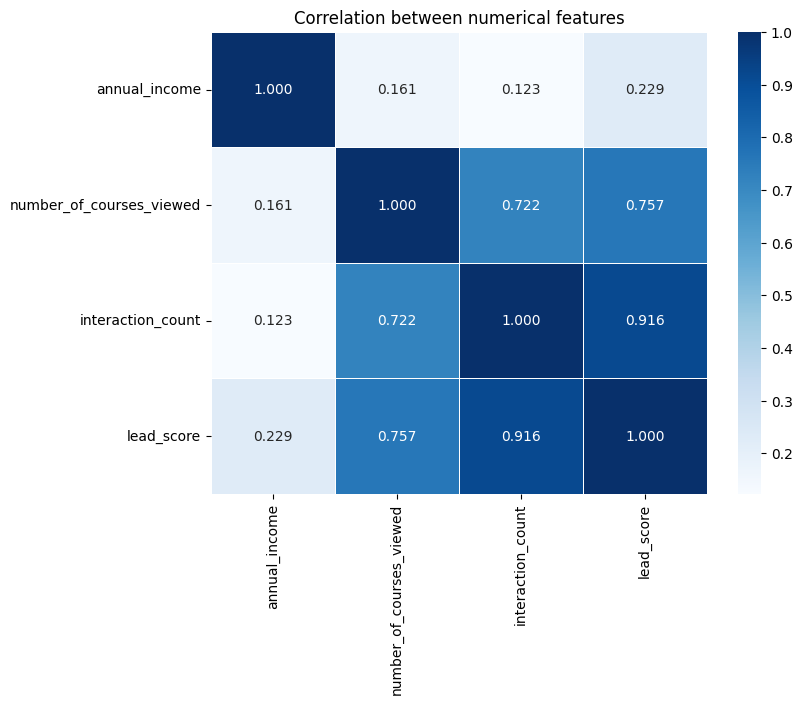

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', linewidths=.5, cmap='Blues')
plt.title('Correlation between numerical features')
plt.show()

In [12]:
pairs = [
    ('interaction_count', 'lead_score'),
    ('number_of_courses_viewed', 'lead_score'),
    ('number_of_courses_viewed', 'interaction_count'),
    ('annual_income', 'interaction_count'),
]

pair_corr = pd.Series({f'{a} & {b}': corr.loc[a, b] for a, b in pairs})
pair_corr = pair_corr.sort_values(key=abs, ascending=False)
pair_corr

interaction_count & lead_score                  0.915746
number_of_courses_viewed & lead_score           0.757204
number_of_courses_viewed & interaction_count    0.721609
annual_income & interaction_count               0.122842
dtype: float64

In [13]:
print('Answer Q2:', pair_corr.index[0])

Answer Q2: interaction_count & lead_score


## Split the data

60% / 20% / 20% with the exact calls from the homework.

In [14]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [15]:
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

df_train = df_train.drop(columns=target)
df_val = df_val.drop(columns=target)
df_test = df_test.drop(columns=target)

assert target not in df_train.columns
assert target not in df_val.columns
assert target not in df_test.columns

## Question 3

Mutual information between `converted` and the categorical variables (training set only), rounded to 2 decimals.

In [16]:
def calculate_mi(series):
    return mutual_info_score(series, y_train)

mi = df_train[categorical].apply(calculate_mi).round(2).sort_values(ascending=False)
mi.to_frame('MI')

,MI
lead_source,0.03
employment_status,0.02
industry,0.00
location,0.00


In [17]:
print('Answer Q3:', mi.index[0])

Answer Q3: lead_source


## Question 4

Logistic regression with one-hot encoding (via `DictVectorizer`), using:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
```

In [18]:
def train_and_evaluate(features, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
    X_val = dv.transform(df_val[features].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    return accuracy_score(y_val, y_pred)

In [19]:
all_features = categorical + numerical

original_score = train_and_evaluate(all_features)
print('Validation accuracy:', original_score)
print('Answer Q4:', round(original_score, 2))

Validation accuracy: 0.645
Answer Q4: 0.65


## Question 5

Feature elimination: drop one feature at a time, retrain, and compute `original_accuracy - accuracy_without_feature`.

> **Note:** the difference doesn't have to be positive.

In [20]:
candidates = ['lead_source', 'number_of_courses_viewed', 'interaction_count']

rows = []
for feature in candidates:
    subset = [f for f in all_features if f != feature]
    score = train_and_evaluate(subset)
    rows.append({
        'eliminated_feature': feature,
        'accuracy': score,
        'difference': original_score - score,
    })

elimination = pd.DataFrame(rows).sort_values('difference')
elimination

,eliminated_feature,accuracy,difference
1,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
2,interaction_count,0.601,0.044


In [21]:
print('Answer Q5:', elimination.iloc[0]['eliminated_feature'])

Answer Q5: number_of_courses_viewed


## Question 6

Regularized logistic regression with `C` in `[0.000001, 0.00001, 0.0001, 0.001]`, accuracy rounded to 3 decimals.

> **Note:** if there are multiple options, select the smallest `C`.

In [22]:
c_scores = {}
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    score = round(train_and_evaluate(all_features, C=C), 3)
    c_scores[C] = score
    print(f'C = {C:<8} accuracy = {score}')

C = 1e-06    accuracy = 0.598
C = 1e-05    accuracy = 0.598
C = 0.0001   accuracy = 0.613
C = 0.001    accuracy = 0.645


In [23]:
# best accuracy; ties broken by the smallest C
best_C = min(c_scores, key=lambda c: (-c_scores[c], c))
print('Answer Q6:', best_C)

Answer Q6: 0.001


## Summary

In [24]:
summary = pd.Series({
    'Q1 – mode of industry': data['industry'].mode()[0],
    'Q2 – most correlated pair': pair_corr.index[0],
    'Q3 – biggest MI': mi.index[0],
    'Q4 – validation accuracy': round(original_score, 2),
    'Q5 – smallest difference': elimination.iloc[0]['eliminated_feature'],
    'Q6 – best C': best_C,
})
summary.to_frame('Answer')

,Answer
Q1 – mode of industry,technology
Q2 – most correlated pair,interaction_count & lead_score
Q3 – biggest MI,lead_source
Q4 – validation accuracy,0.65
Q5 – smallest difference,number_of_courses_viewed
Q6 – best C,0.001
